In [1]:
#Import Libraries

import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats.mstats import winsorize
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [2]:
#Read Dataset
df = pd.read_csv("datasets_11167_15520_train.csv")

In [3]:
df.shape

(2000, 21)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

In [5]:
df.describe()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


In [6]:
columns = df.columns 
for col in columns:
    value_count = df[col].value_counts()
    print(value_count)

battery_power
1589    6
1872    6
618     6
772     5
1063    5
       ..
590     1
544     1
1279    1
1749    1
1405    1
Name: count, Length: 1094, dtype: int64
blue
0    1010
1     990
Name: count, dtype: int64
clock_speed
0.5    413
2.8     85
2.3     78
2.1     76
1.6     76
2.5     74
0.6     74
1.4     70
1.3     68
1.5     67
2.0     67
1.9     65
0.7     64
1.8     62
2.9     62
1.0     61
1.7     60
2.2     59
0.8     58
2.4     58
0.9     58
1.2     56
2.6     55
2.7     55
1.1     51
3.0     28
Name: count, dtype: int64
dual_sim
1    1019
0     981
Name: count, dtype: int64
fc
0     474
1     245
2     189
3     170
5     139
4     133
6     112
7     100
9      78
8      77
10     62
11     51
12     45
13     40
16     24
15     23
14     20
18     11
17      6
19      1
Name: count, dtype: int64
four_g
1    1043
0     957
Name: count, dtype: int64
int_memory
27    47
14    45
16    45
2     42
57    42
      ..
25    24
38    23
62    21
4     20
59    18
Name: count, L

In [7]:
df1 = df
X = df1.drop('price_range', axis=1)

# Initialize scaler
scaler = StandardScaler()

# Scale features
X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

print(X_scaled.head())

   battery_power      blue  clock_speed  dual_sim        fc    four_g  \
0      -0.902597 -0.990050     0.830779 -1.019184 -0.762495 -1.043966   
1      -0.495139  1.010051    -1.253064  0.981177 -0.992890  0.957886   
2      -1.537686  1.010051    -1.253064  0.981177 -0.532099  0.957886   
3      -1.419319  1.010051     1.198517 -1.019184 -0.992890 -1.043966   
4       1.325906  1.010051    -0.395011 -1.019184  2.002254  0.957886   

   int_memory     m_dep  mobile_wt   n_cores        pc  px_height  px_width  \
0   -1.380644  0.340740   1.349249 -1.101971 -1.305750  -1.408949 -1.146784   
1    1.155024  0.687548  -0.120059 -0.664768 -0.645989   0.585778  1.704465   
2    0.493546  1.381165   0.134244  0.209639 -0.645989   1.392684  1.074968   
3   -1.215274  1.034357  -0.261339  0.646842 -0.151168   1.286750  1.236971   
4    0.658915  0.340740   0.021220 -1.101971  0.673534   1.268718 -0.091452   

        ram      sc_h      sc_w  talk_time   three_g  touch_screen      wifi  
0  0.39

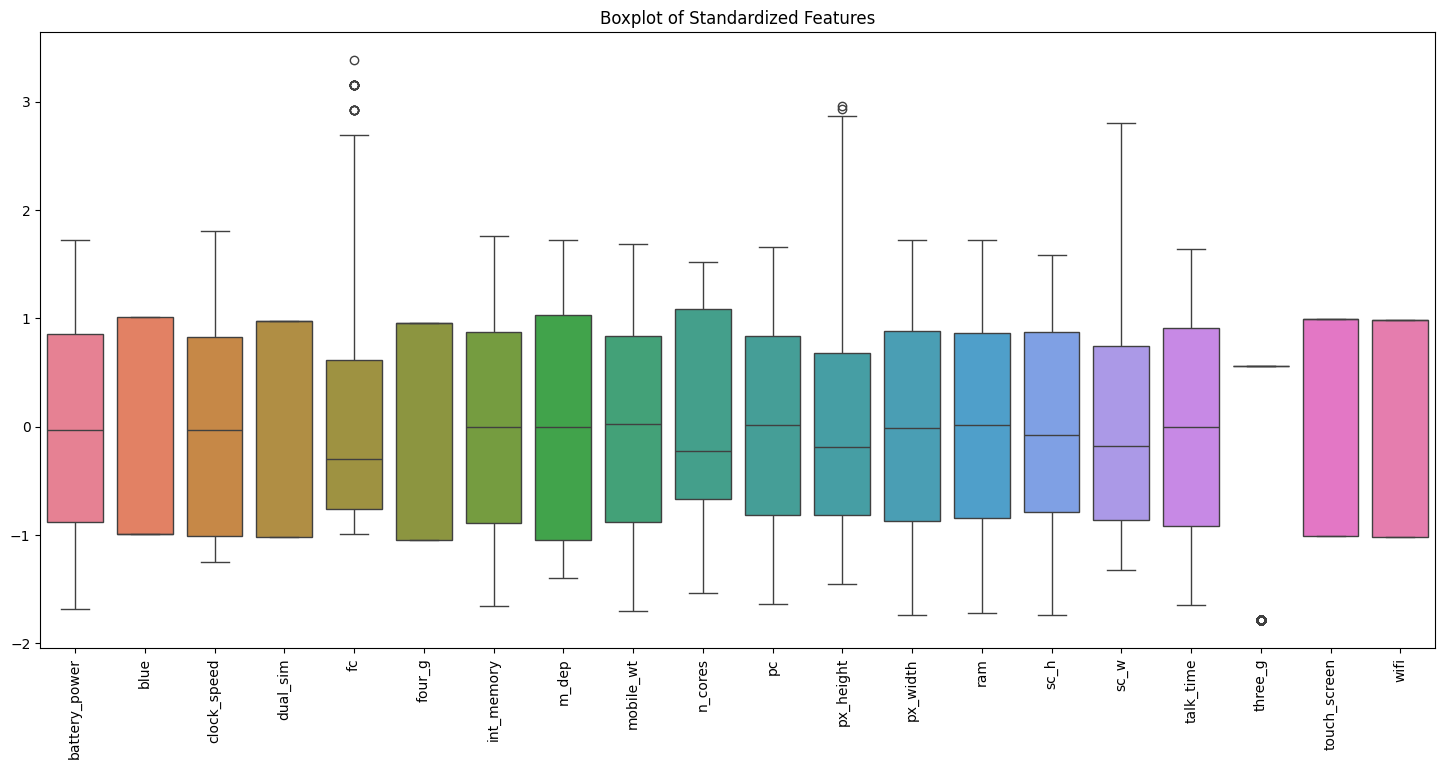

In [8]:
#Outlier Detection
plt.figure(figsize=(18,8))

sns.boxplot(data=X_scaled)

plt.xticks(rotation=90)
plt.title("Boxplot of Standardized Features")

plt.show()

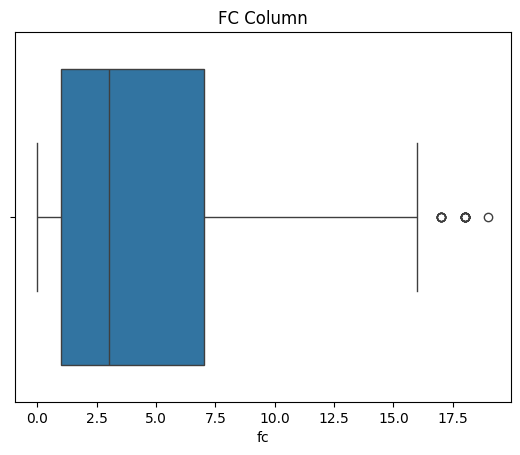

In [9]:
#Outlier Hanling
sns.boxplot(x=df['fc'])
plt.title("FC Column")
plt.show()

In [10]:
df['fc'] = winsorize(df['fc'], limits=[0.05, 0.05])

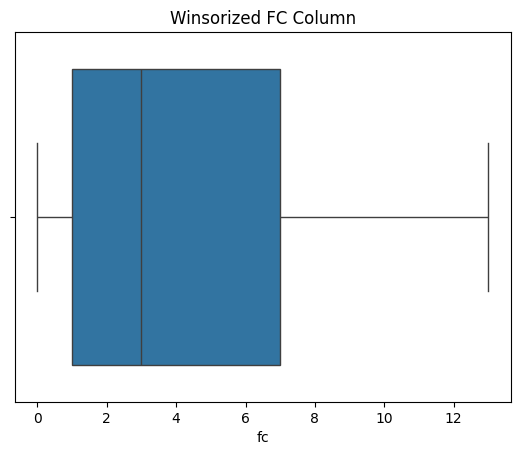

In [11]:
sns.boxplot(x=df['fc'])
plt.title("Winsorized FC Column")
plt.show()

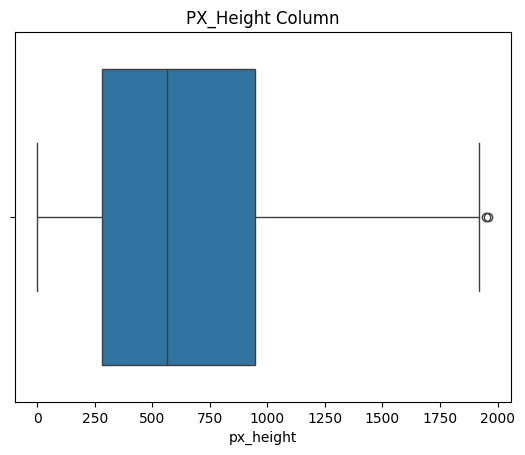

In [12]:
sns.boxplot(x=df['px_height'])
plt.title("PX_Height Column")
plt.show()

In [13]:
df['px_height'] = winsorize(df['px_height'], limits=[0.05, 0.05])

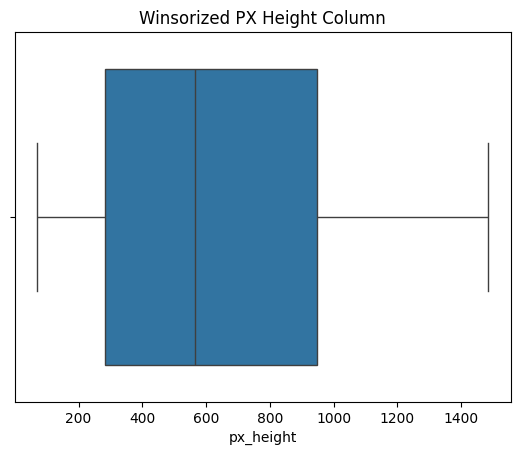

In [14]:
sns.boxplot(x=df['px_height'])
plt.title("Winsorized PX Height Column")
plt.show()

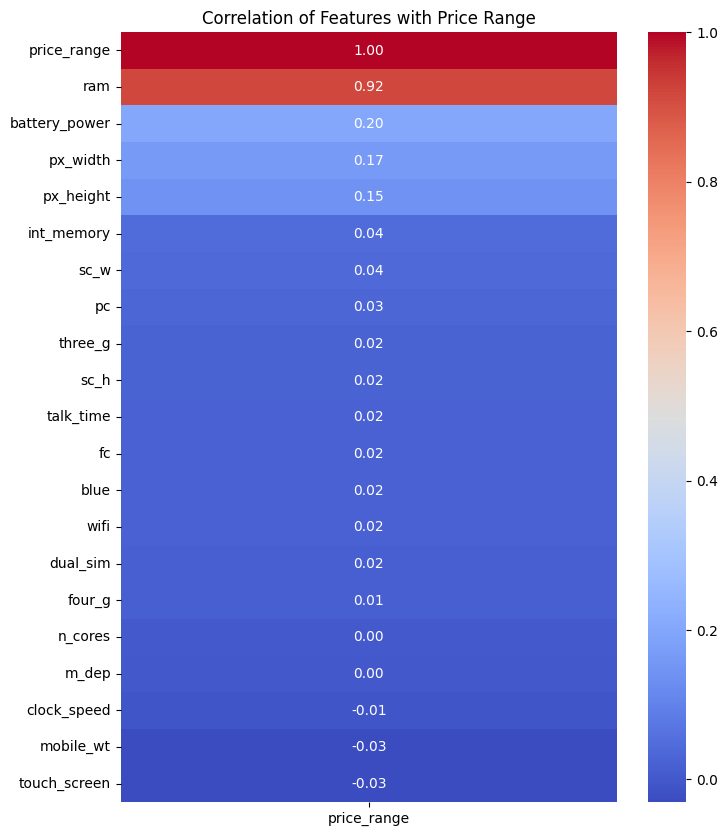

In [15]:
#Relation of features with the target varibale
plt.figure(figsize=(8,10))

corr = df.corr()[['price_range']].sort_values(
    by='price_range',
    ascending=False
)

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation of Features with Price Range")

plt.show()

In [16]:
#Splitting Data
X = df.drop('price_range', axis=1)
y = df['price_range']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [17]:
#Scaling Data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

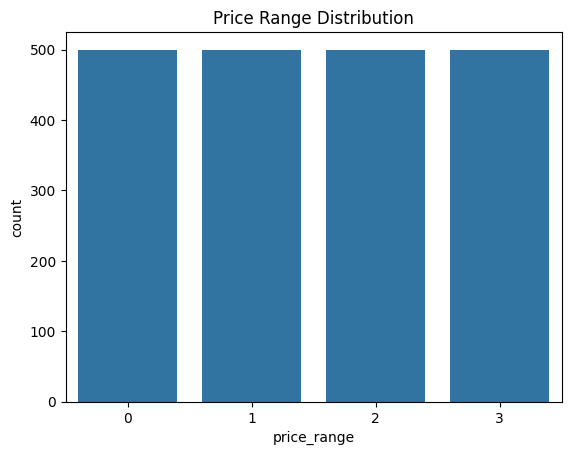

In [18]:
#Class Distribution
sns.countplot(x='price_range', data=df)
plt.title("Price Range Distribution")
plt.show()

In [19]:
#Applying Logostic Regression
lr = LogisticRegression()

lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_lr)
print("Confusion Matrix:")
print(cm)

# Classification Report
cr = classification_report(y_test, y_pred_lr)
print("\nClassification Report:")
print(cr)

Accuracy: 0.975
Confusion Matrix:
[[103   2   0   0]
 [  1  90   0   0]
 [  0   3  86   3]
 [  0   0   1 111]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       105
           1       0.95      0.99      0.97        91
           2       0.99      0.93      0.96        92
           3       0.97      0.99      0.98       112

    accuracy                           0.97       400
   macro avg       0.97      0.97      0.97       400
weighted avg       0.98      0.97      0.97       400



In [20]:
#Applying KNN 
knn = KNeighborsClassifier()

knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_knn)
print("Confusion Matrix:")
print(cm)

# Classification Report
cr = classification_report(y_test, y_pred_knn)
print("\nClassification Report:")
print(cr)

Accuracy: 0.54
Confusion Matrix:
[[74 26  5  0]
 [24 43 20  4]
 [ 5 36 39 12]
 [ 2 13 37 60]]

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.70      0.70       105
           1       0.36      0.47      0.41        91
           2       0.39      0.42      0.40        92
           3       0.79      0.54      0.64       112

    accuracy                           0.54       400
   macro avg       0.56      0.53      0.54       400
weighted avg       0.58      0.54      0.55       400



In [21]:
#Applying Decision Tree
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_dt)
print("Confusion Matrix:")
print(cm)

# Classification Report
cr = classification_report(y_test, y_pred_dt)
print("\nClassification Report:")
print(cr)

Accuracy: 0.8225
Confusion Matrix:
[[93 12  0  0]
 [10 72  9  0]
 [ 0 16 65 11]
 [ 0  0 13 99]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.89      0.89       105
           1       0.72      0.79      0.75        91
           2       0.75      0.71      0.73        92
           3       0.90      0.88      0.89       112

    accuracy                           0.82       400
   macro avg       0.82      0.82      0.82       400
weighted avg       0.82      0.82      0.82       400



In [22]:
#Applying Random Forest
rf = RandomForestClassifier(random_state=42)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_rf)
print("Confusion Matrix:")
print(cm)

# Classification Report
cr = classification_report(y_test, y_pred_rf)
print("\nClassification Report:")
print(cr)

Accuracy: 0.89
Confusion Matrix:
[[100   5   0   0]
 [  6  78   7   0]
 [  0   9  77   6]
 [  0   0  11 101]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95       105
           1       0.85      0.86      0.85        91
           2       0.81      0.84      0.82        92
           3       0.94      0.90      0.92       112

    accuracy                           0.89       400
   macro avg       0.89      0.89      0.89       400
weighted avg       0.89      0.89      0.89       400



In [23]:
#Applying SVM 
svm = SVC()

svm.fit(X_train_scaled, y_train)

y_pred_svm = svm.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_svm)
print("Confusion Matrix:")
print(cm)

# Classification Report
cr = classification_report(y_test, y_pred_svm)
print("\nClassification Report:")
print(cr)

Accuracy: 0.89
Confusion Matrix:
[[ 98   7   0   0]
 [  5  80   6   0]
 [  0  13  74   5]
 [  0   0   8 104]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.93      0.94       105
           1       0.80      0.88      0.84        91
           2       0.84      0.80      0.82        92
           3       0.95      0.93      0.94       112

    accuracy                           0.89       400
   macro avg       0.89      0.89      0.89       400
weighted avg       0.89      0.89      0.89       400



In [24]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'KNN',
        'Decision Tree',
        'Random Forest',
        'SVM'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_svm)
    ]
})

results.sort_values(by='Accuracy', ascending=False)

,Model,Accuracy
0,Logistic Regression,0.9750
4,SVM,0.8900
3,Random Forest,0.8900
2,Decision Tree,0.8225
1,KNN,0.5400


In [25]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

importance

,Feature,Importance
13,ram,0.462289
0,battery_power,0.073909
12,px_width,0.056926
11,px_height,0.056480
8,mobile_wt,0.041759
6,int_memory,0.040999
16,talk_time,0.033230
10,pc,0.030787
2,clock_speed,0.030043
14,sc_h,0.029725


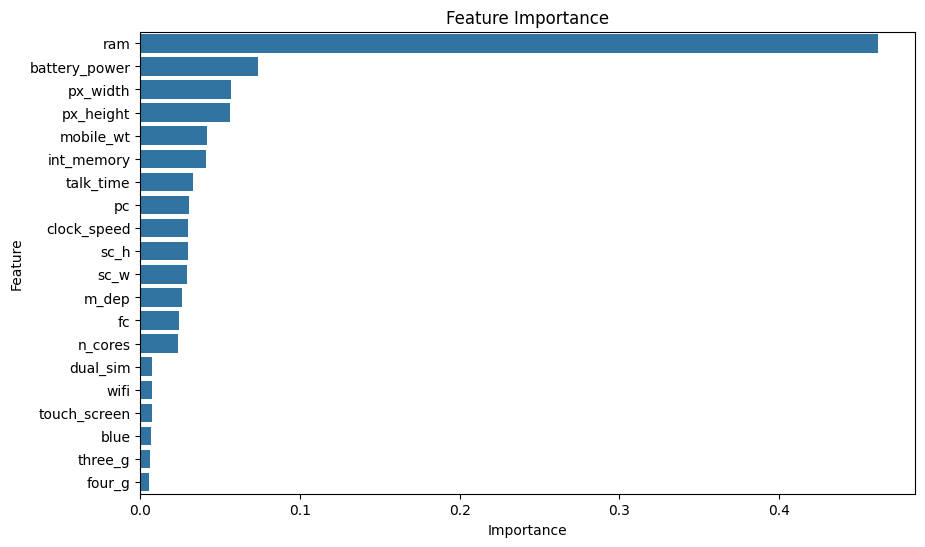

In [26]:
plt.figure(figsize=(10,6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=importance
)

plt.title("Feature Importance")

plt.show()

Data Analysis Report 

1. No missing values detected.
2. The cluster box chart shows that some columns have outliers which are handled using winsorization.
3. The classication data is balanced.
4. From the heatmap we can see that RAM has the highest correlation with price which means that higher the ram higher the price range. Some other features such as batter power, internal memory, pixel width, pixel height also have a positive correlation with the price range. While some features like clock speed, mobile weight etc have a negative correlation with the data. 

Business Insights

1. The model helps us understand accurate mobile pricing according to features.
2. Better product planning according to the price range.
3. Understanding customer expectations from the product depending on the price.
4. Understanding which features are crucial for production of a good phone.
5. Competitor Analysis

Model Evaluation 

We have used 5 models to predict the price range which are logistic regression, random forest, decision tree, knn and svm .
Logistic Regression gives us the best prediction results which is robust to the data that we provided. The other models lacked accuracy due to data sensitivity. 